# 07 — Combining the CNN and the SVM

`06_cnn_vs_classic.ipynb` showed that the CNN and the SVM are wrong on partly different songs: 26 % of the test songs are classified correctly by only one of them. This notebook checks whether that complementarity can be turned into a better model, and whether evaluating the CNN on more crops per clip helps. Both were computed by `src/fusion.py`, which trains nothing new:

- **more crops:** the CNN averages its probabilities over 10-second crops taken every 5 s (6 crops, as in training) or every 2.5 s (9 crops);
- **SVM probabilities:** the SVM with the hyperparameters of `experiments_classic.py` gives decision scores, which are turned into class probabilities by sigmoid calibration fitted with 5-fold cross-validation on the training set only;
- **fusion:** `w · p_CNN + (1 − w) · p_SVM`, with `w` from 0 to 1 in steps of 0.1.

On each split, the number of crops and the weight `w` are chosen on the **validation** set (ties go to fewer crops and to the higher CNN weight, so the fusion is used only if it is strictly better than the CNN alone); the test set is evaluated once. A fixed 50/50 fusion is reported as a rule that involves no choice at all. Tables and figures are saved to `results/fusion/figures/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FUS = ROOT / "results" / "fusion"
OUT = FUS / "figures"
OUT.mkdir(parents=True, exist_ok=True)
QUADRANTS = ["Q1", "Q2", "Q3", "Q4"]
ORDER = ["svm_calibrated", "cnn", "cnn_tta", "fusion", "fusion_equal"]
LABELS = {"svm_calibrated": "SVM (calibrated)", "cnn": "CNN (6 crops)", "cnn_tta": "CNN (crops chosen on validation)",
          "fusion": "CNN + SVM (weight chosen on validation)", "fusion_equal": "CNN + SVM (50/50)"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

runs = pd.read_csv(FUS / "runs.csv")
grid = pd.read_csv(FUS / "validation_grid.csv")
preds = pd.read_csv(FUS / "test_predictions.csv", dtype={"Song": str})
info = json.loads((FUS / "info.json").read_text(encoding="utf-8"))
summary = {}
print(info["created"], "|", info["elapsed_minutes"], "min")

2026-11-22T23:50:02 | 22.7 min


## 1. What was chosen on validation

In [2]:
chosen = runs[runs.model == "fusion"][["protocol", "hop_seconds", "weight_cnn"]].set_index("protocol")
chosen["crops"] = np.where(chosen["hop_seconds"] == 5.0, 6, 9)
chosen.to_csv(OUT / "01_choices.csv")
summary["weights_chosen"] = chosen["weight_cnn"].to_dict()
chosen

,hop_seconds,weight_cnn,crops
protocol,,,
A,5.0,1.0,6
B42,2.5,1.0,9
B43,5.0,1.0,6
B44,5.0,1.0,6
B45,5.0,0.8,6
B46,5.0,0.9,6


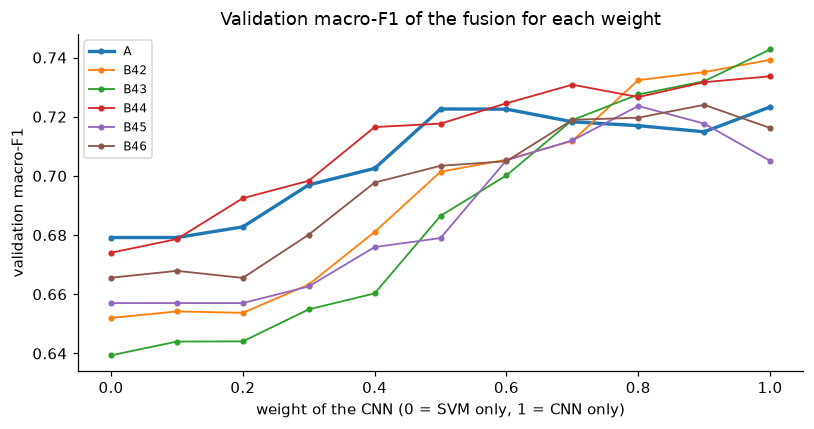

In [3]:
w = grid[grid.kind == "fusion_weight"]
fig, ax = plt.subplots(figsize=(7.5, 4))
for p, g in w.groupby("protocol"):
    ax.plot(g.weight_cnn, g.val_macro_f1, marker="o", markersize=3, label=p, linewidth=2.2 if p == "A" else 1.2)
ax.set_xlabel("weight of the CNN (0 = SVM only, 1 = CNN only)")
ax.set_ylabel("validation macro-F1")
ax.set_title("Validation macro-F1 of the fusion for each weight")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "01_validation_by_weight.png", bbox_inches="tight")
plt.show()

## 2. Test results

In [4]:
per_split = runs.pivot(index="protocol", columns="model", values="test_macro_f1")[ORDER]
per_split.round(4).to_csv(OUT / "02_test_per_split.csv")
b = runs[runs.protocol != "A"]
table = b.groupby("model").agg(macro_f1_mean=("test_macro_f1", "mean"), macro_f1_sd=("test_macro_f1", "std"),
                               accuracy_mean=("test_accuracy", "mean"), q3_q4_confusions_mean=("test_q3_q4", "mean"),
                               **{f"f1_{q}": (f"test_f1_{q}", "mean") for q in QUADRANTS}).loc[ORDER]
table.round(4).to_csv(OUT / "02_test_protocol_B.csv")
summary["B_mean"] = table["macro_f1_mean"].round(4).to_dict()
summary["B_sd"] = table["macro_f1_sd"].round(4).to_dict()
display(per_split.round(3))
table.round(3)

model,svm_calibrated,cnn,cnn_tta,fusion,fusion_equal
protocol,,,,,
A,0.673,0.682,0.682,0.682,0.682
B42,0.652,0.701,0.703,0.703,0.684
B43,0.684,0.686,0.686,0.686,0.701
B44,0.662,0.665,0.665,0.665,0.684
B45,0.663,0.708,0.708,0.724,0.696
B46,0.662,0.709,0.709,0.715,0.686


,macro_f1_mean,macro_f1_sd,accuracy_mean,q3_q4_confusions_mean,f1_Q1,f1_Q2,f1_Q3,f1_Q4
model,,,,,,,,
svm_calibrated,0.665,0.011,0.670,70.4,0.697,0.854,0.528,0.580
cnn,0.694,0.018,0.698,75.6,0.765,0.886,0.558,0.567
cnn_tta,0.694,0.019,0.699,75.4,0.765,0.887,0.557,0.568
fusion,0.699,0.024,0.703,73.0,0.766,0.887,0.564,0.577
fusion_equal,0.690,0.008,0.696,71.2,0.749,0.885,0.545,0.583


## 3. Is any gain significant? (McNemar)

The fusion and the CNN are compared song by song on each test set and on the five artist splits pooled, as in `06_cnn_vs_classic.ipynb`. Where the chosen weight is 1, the fusion is the CNN itself and the two models never disagree.

In [5]:
def mcnemar(frame, left, right):
    l = frame[frame.model == left].set_index("Song")
    r = frame[frame.model == right].set_index("Song").loc[l.index]
    ok_l, ok_r = l["pred"] == l["true"], r["pred"] == r["true"]
    b_, c_ = int((ok_l & ~ok_r).sum()), int((~ok_l & ok_r).sum())
    return b_, c_, (stats.binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ else 1.0)


rows = []
for protocol, frame in preds.groupby("protocol"):
    for left, right in [("fusion", "cnn"), ("fusion_equal", "cnn"), ("cnn_tta", "cnn"), ("fusion", "svm_calibrated")]:
        b_, c_, p = mcnemar(frame, left, right)
        rows.append({"protocol": protocol, "comparison": f"{left} vs {right}", "only_left_correct": b_, "only_right_correct": c_, "p_value": p})
mc = pd.DataFrame(rows)
mc.round(4).to_csv(OUT / "03_mcnemar.csv", index=False)
pooled = mc[mc.protocol != "A"].groupby("comparison")[["only_left_correct", "only_right_correct"]].sum()
pooled["p_value"] = [stats.binomtest(int(x), int(x + y), 0.5).pvalue if x + y else 1.0 for x, y in zip(pooled.only_left_correct, pooled.only_right_correct)]
pooled.round(4).to_csv(OUT / "03_mcnemar_pooled_B.csv")
summary["pooled_p"] = pooled["p_value"].round(4).to_dict()
display(mc.pivot(index="comparison", columns="protocol", values="p_value").round(3))
pooled.round(4)

protocol,A,B42,B43,B44,B45,B46
comparison,,,,,,
cnn_tta vs cnn,1.000,1.000,1.000,1.000,1.000,1.000
fusion vs cnn,1.000,1.000,1.000,1.000,0.256,0.549
fusion vs svm_calibrated,0.719,0.031,1.000,1.000,0.003,0.032
fusion_equal vs cnn,1.000,0.386,0.477,0.374,0.749,0.368


,only_left_correct,only_right_correct,p_value
comparison,,,
cnn_tta vs cnn,8,7,1.0000
fusion vs cnn,38,26,0.1686
fusion vs svm_calibrated,320,242,0.0011
fusion_equal vs cnn,199,205,0.8036


## 4. Why does complementarity not translate into a large gain?

For the songs on which the CNN and the SVM disagree, the fusion can only help if the model that is right is also the more confident one. The table shows, among the songs where exactly one of the two is right, how often the correct model gives its predicted class a higher probability than the wrong model gives to its own prediction.

In [6]:
rows = []
for protocol, frame in preds[preds.protocol != "A"].groupby("protocol"):
    c = frame[frame.model == "cnn"].set_index("Song")
    s = frame[frame.model == "svm_calibrated"].set_index("Song").loc[c.index]
    pc = c[[f"prob_{q}" for q in QUADRANTS]].max(axis=1)
    ps = s[[f"prob_{q}" for q in QUADRANTS]].max(axis=1)
    ok_c, ok_s = c["pred"] == c["true"], s["pred"] == s["true"]
    only_c, only_s = ok_c & ~ok_s, ~ok_c & ok_s
    rows.append({"protocol": protocol, "only_cnn_right": int(only_c.sum()), "cnn_more_confident_when_only_cnn_right": float((pc[only_c] > ps[only_c]).mean()),
                 "only_svm_right": int(only_s.sum()), "svm_more_confident_when_only_svm_right": float((ps[only_s] > pc[only_s]).mean()),
                 "mean_top_probability_cnn": float(pc.mean()), "mean_top_probability_svm": float(ps.mean())})
conf = pd.DataFrame(rows).set_index("protocol")
conf.round(3).to_csv(OUT / "04_confidence_on_disagreements.csv")
summary["confidence"] = conf.mean().round(3).to_dict()
conf.round(3)

,only_cnn_right,cnn_more_confident_when_only_cnn_right,only_svm_right,svm_more_confident_when_only_svm_right,mean_top_probability_cnn,mean_top_probability_svm
protocol,,,,,,
B42,73,0.370,49,0.755,0.685,0.635
B43,61,0.459,60,0.633,0.726,0.634
B44,62,0.371,61,0.787,0.678,0.622
B45,65,0.246,46,0.913,0.638,0.634
B46,73,0.425,52,0.673,0.688,0.636


## 5. Summary of the numbers used in the findings

In [7]:
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
summary

{'weights_chosen': {'A': 1.0,
  'B42': 1.0,
  'B43': 1.0,
  'B44': 1.0,
  'B45': 0.8,
  'B46': 0.9},
 'B_mean': {'svm_calibrated': 0.6646,
  'cnn': 0.6939,
  'cnn_tta': 0.6942,
  'fusion': 0.6986,
  'fusion_equal': 0.6902},
 'B_sd': {'svm_calibrated': 0.0115,
  'cnn': 0.0184,
  'cnn_tta': 0.0186,
  'fusion': 0.0235,
  'fusion_equal': 0.0081},
 'pooled_p': {'cnn_tta vs cnn': 1.0,
  'fusion vs cnn': 0.1686,
  'fusion vs svm_calibrated': 0.0011,
  'fusion_equal vs cnn': 0.8036},
 'confidence': {'only_cnn_right': 66.8,
  'cnn_more_confident_when_only_cnn_right': 0.374,
  'only_svm_right': 53.6,
  'svm_more_confident_when_only_svm_right': 0.752,
  'mean_top_probability_cnn': 0.683,
  'mean_top_probability_svm': 0.632}}

## 6. Findings

Numbers below come from the tables above; *protocol B* means mean ± standard deviation over the five artist-grouped splits.

**1. More crops do not help.** Evaluating the CNN on 9 crops (every 2.5 s) instead of 6 was preferred on validation only on B42, and changed the test macro-F1 there by +0.002; over the five splits the mean moves from 0.6939 to 0.6942 and only 15 test songs change outcome (8 gained, 7 lost). Six crops already cover the whole clip with overlap, so averaging more crops adds almost no new information.

**2. A weighted fusion is chosen on two of five splits and gives a small, non-significant gain.** On validation, the best weight is 1 (CNN alone) on A, B42, B43 and B44, 0.8 on B45 and 0.9 on B46. On protocol B the fusion reaches 0.699 ± 0.024 against 0.694 ± 0.018 for the CNN alone (+0.005); pooled over the splits it is right where the CNN is wrong on 38 songs and the opposite on 26 (McNemar p = 0.17). It remains clearly better than the SVM (pooled p = 0.001), as the CNN alone is.

**3. An equal 50/50 fusion is not better on average but is more stable.** It scores 0.690 ± 0.008 on protocol B: 0.004 below the CNN on average, with no difference on the song level (199 against 205, p = 0.80), but with less than half the variation between splits and fewer sad/calm confusions (71.2 against 75.6 per split). Its scores move in the opposite direction from the CNN's: it is better on the splits where the CNN is weakest (B43, B44) and worse where the CNN is strongest (B42, B45, B46).

**4. Why the 26 % of songs that only one model gets right do not become a large gain.** For the fusion to help, the model that is right has to be the more confident one. When only the SVM is right, it is more confident than the CNN in 75 % of cases; but when only the CNN is right, it is more confident than the SVM in only 37 % of cases, so a fusion that rescues the first group loses part of the second. The CNN is also more confident overall (mean top probability 0.68 against 0.63), so its wrong answers are not easy to override.

**Decision (D18).** The final deep-learning model stays the CNN alone, evaluated on 6 crops: neither more crops nor the fusion gives a gain that is significant or consistent across splits, and the simpler model is easier to explain and to deploy. The fusion results are reported as an explored and rejected option; the lower variability of the equal-weight fusion is noted as a possible direction for future work.